# Project Work - 2

- *Streamlit App* https://ind320-dakshi.streamlit.app
- *GitHub repo* https://github.com/dakshiken/IND320

## General
- If you push new updates to the main branch of your GitHub repository before the peer review and teacher feedback, things will get cluttered.
    - Create and use a new branch in the GitHub repository for new updates.
    - When peer review and feedback are finished, merge your changes into the main branch.
- All project work in IND320 will result in personal hand-ins and online apps.
    1. A Jupyter Notebook run locally on your computer.
        - This will be your basic development and documentation platform.
            - Must include a brief description of AI usage.
            - Must include a 300-500-word log describing the compulsory work (including both Jupyter Notebook and Streamlit experience).
            - Must include links to your public GitHub repository and Streamlit app (see below) for the compulsory work.
        - Document headings should be clear and usable for navigation during development.
        - All code blocks must include enough comments to be understandable and reproducible if someone inherits your project.
        - All code blocks must be run before an export to PDF so the messages and plots are shown. In addition, add the .ipynb file to the GitHub repository where you have your Streamlit project.
    2. A Streamlit app running at https://[yourproject].streamlit.app/.
        - This is an online version of the project, accessing your MongoDB database for data.
        - The code, hosted on GitHub, must include relevant comments from the Jupyter Notebook and further comments regarding Streamlit usage.
- There are four parts in the project work, building on each other and resulting in a final portfolio and app to be presented at the end of the semester.
- Co-operation is applauded, and the use of AI tools is encouraged.

## Tasks
### Accounts and repositories
- Reuse your account, repository and Streamlit app from the previous part of the project work.
- Until peer review and feedback have been completed, push to a temporary GitHub branch for later merging.

### Local database: Cassandra
- If not already done, set up Cassandra and Spark as described in the book.
- Test that your Spark-Cassandra connection works.
- The Cassandra database will be accessed from the Jupyter Notebook and used to store data from the APIs mentioned later. 

### 1. Run cassandra

In [1]:
#run docker Daemon
!open -a Docker

In [2]:
# sleep to let docker daemon start up
from time import sleep
sleep(20)

In [3]:
# run cassandra
!docker start cassandra

cassandra


In [4]:
#cassandra start up
from time import sleep
#wait for Cassandra to finish starting up
sleep(45)


In [5]:
#load secrets and environment variables from the .env file in the project root
from dotenv import load_dotenv
load_dotenv("../.env")

True

### 2. Start Spark

In [6]:
import os, platform, subprocess

if platform.system() == "Darwin": 
    os.environ["JAVA_HOME"] = subprocess.check_output(["/usr/libexec/java_home", "-v", "11"], text=True).strip()

from pyspark.sql import SparkSession
spark = (SparkSession.builder.appName("SparkCassandraApp")
         .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
         .config("spark.cassandra.connection.host", "localhost")
         .config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions")
         .config("spark.sql.catalog.mycatalog", "com.datastax.spark.connector.datasource.CassandraCatalog")
         .config("spark.cassandra.connection.port", "9042")
         .getOrCreate())

26/10/20 19:54:28 WARN Utils: Your hostname, Dakshiken-sin-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.0.114 instead (on interface en0)
26/10/20 19:54:28 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/dakshikensanthakumar/.ivy2/cache
The jars for the packages stored in: /Users/dakshikensanthakumar/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-56b11e2e-0401-4630-868f-bff99f8b2b98;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central


:: loading settings :: url = jar:file:/Users/dakshikensanthakumar/Downloads/IND320/.venv/lib/python3.13/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassandra#java-driver-query-builder;4.18.1 in central
	found org.apache.commons#commons-lang3;3.10 in central
	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found org.scala-lang#scala-reflect;2.12.19 in central
:: resolution report :: resolve 226ms :: artifacts dl 

### Remote database: MongoDB
- If not already done, prepare a MongoDB account at mongodb.com.
- Test that you can manipulate data from Python.
- The MongoDB database will store data that has been trimmed/curated/prepared through the Jupyter Notebook and Spark filtering.
- These data will be accessed directly from the Streamlit app.

### 3. Setup Mongo connection

In [7]:
from pymongo import MongoClient
client = MongoClient(os.getenv("MONGO_URI"))
try:
    client.admin.command("ping")
    print("Connected successfully")
    client.close()

except Exception as e:
    raise Exception(
        "The following error occurred: ", e)

Connected successfully


## API
- Familiarise yourself with the API at [Magasinstatistikk API](https://biapi.nve.no/magasinstatistikk/swagger/index.html) and the descriptions at [NVE Magasinstatistikk](https://www.nve.no/energi/analyser-og-statistikk/magasinstatistikk/)
    - Remember your experiences regarding the time columns from part 1 of the project.
    - Identify the areas of Norway covered by the different API.
- Familiarise yourself with the API in the [ENTSO-E API reference](https://documenter.getpostman.com/view/7009892/2s93JtP3F6) and its account handling and graphical user interface at [ENTSO-E](https://transparency.entsoe.eu/)
    - Create an account and [obtain a security token](https://transparencyplatform.zendesk.com/hc/en-us/articles/12845911031188-How-to-get-security-token).

### <font color="green">Answer to the task:</font>

#### NVE Reservoir Statistics API
* **Endpoints:** All use GET and don't need parameters. Grab the full history with `HentOffentligData`, just the latest week with `HentOffentligDataSisteUke`, a 20-year min/max/median overview via `HentOffentligDataMinMaxMedian`, or the location list with `HentOmråder`.
* **Dates & Times:** The `dato_Id` column is always a Sunday. Use `iso_aar` and `iso_uke` for standard ISO years and weeks. The `neste_Publiseringsdato` shows the next update (older rows use `0001-01-01` as a filler). New data drops every Wednesday at 1:00 PM.
* **Areas:** Covers roughly 490 reservoirs split into three groups:
 * Entire country: `omrType = "NO"`, `omrnr = 0`
 * 5 bidding zones (NO 1 to NO 5): `omrType = "EL"`, `omrnr` 1–5
 * 4 watercourse areas: `omrType = "VASS"`, `omrnr` 1–4


#### ENTSO-E API
* **Account and token:** I created an account, emailed entsoe to activate api access and generated a security token. The token is stored in the `.env` file as `ENTSOE_API_TOKEN` (not pushed to GitHub).
* **Areas:** Norway is covered by the five bidding zones NO_1 to NO_5. Cross border flows are requested for a pair of zones and one direction at a time (for example NO_2 to DK_1).

In [8]:
import requests
import pandas as pd

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
areas = requests.get(f"{BASE}/HentOmr%C3%A5der", timeout=30).json()[0]    
areas = pd.DataFrame([{"group": g, **a} for g, items in areas.items() for a in items])
areas[["group", "omrType", "omrnr", "navn", "beskrivelse"]]

,group,omrType,omrnr,navn,beskrivelse
0,land,NO,0,Norge,Hele landet
1,elspot,EL,1,NO 1,Sørøst-Norge. Omfatter østlige del av Østlande...
2,elspot,EL,2,NO 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
3,elspot,EL,3,NO 3,Midt-Norge. Omfatter nordre og vestlige del av...
4,elspot,EL,4,NO 4,Nord-Norge. Omfatter resten av Trøndelag og No...
5,elspot,EL,5,NO 5,Vest-Norge. Omfatter midtre del av Vestland op...
6,vassdrag,VASS,1,VASS1,"Sørøst-Norge. Østlandet, Agder og deler av Rog..."
7,vassdrag,VASS,2,VASS2,Vest-Norge. Resten av Rogaland og Vestland.
8,vassdrag,VASS,3,VASS3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl..."
9,vassdrag,VASS,4,VASS4,Nord-Norge. Resten av Nordland og nordover.


## Jupyter Notebook
- Remove your CSV-file for the Magasinstatistikk and use a direct API connection instead.
   - Recreate the associated plots from part 1 of the project using the API connection.
- Use the ENTSO-E API to retrieve cross-border transfer data from/to Norway for the last two years.
   - Insert the data into Cassandra using Spark.
- Use Spark to extract relevant columns from Cassandra.
- Create the following plots:
   - A pie chart for the total production of one year from a chosen connection, where each piece of the pie is the amount in and out of Norway.
   - A line plot for the first month of a year for a chosen connection. Make separate lines for each connection and direction.
- Insert the Spark-extracted data into your MongoDB.
- Remember to fill in the log and AI mentioned in the General section above.

### 4. Reservoir data from the NVE API
The CSV file is replaced by a direct connection to the NVE Magasinstatistikk API.
Below I recreate the plots from Part 1 using the national series

In [9]:
#read the national series directly from the nve api instead of the csv file
df = pd.DataFrame(requests.get(f"{BASE}/HentOffentligData", timeout=30).json())
df = df[(df["omrType"] == "NO") & (df["omrnr"] == 0)].rename(columns={
    "dato_Id": "Date", "fyllingsgrad": "Fill Degree", "kapasitet_TWh": "Capacity (TWh)", "fylling_TWh": "Fill Volume (TWh)",
    "fyllingsgrad_forrige_uke": "Fill Degree Previous Week", "endring_fyllingsgrad": "Change in Fill Degree"})
df["Date"] = pd.to_datetime(df["Date"])      # dato_Id: the Sunday of each week
cols = ["Fill Degree", "Capacity (TWh)", "Fill Volume (TWh)", "Fill Degree Previous Week", "Change in Fill Degree"]
df = df[["Date"] + cols].sort_values("Date").reset_index(drop=True)
print(df["Date"].min().date(), "->", df["Date"].max().date())
df.head()

1995-01-08 -> 2026-10-11


,Date,Fill Degree,Capacity (TWh),Fill Volume (TWh),Fill Degree Previous Week,Change in Fill Degree
0,1995-01-08,0.607988,87.43758,53.161003,0.752631,-0.144643
1,1995-01-15,0.582088,87.43758,50.896374,0.607988,-0.025900
2,1995-01-22,0.562121,87.43758,49.150486,0.582088,-0.019967
3,1995-01-29,0.534222,87.43758,46.711033,0.562121,-0.027899
4,1995-02-05,0.506221,87.43758,44.262720,0.534222,-0.028001


#### Each column separately
The columns have very different scales (fractions vs. TWh), so each gets its own subplot.

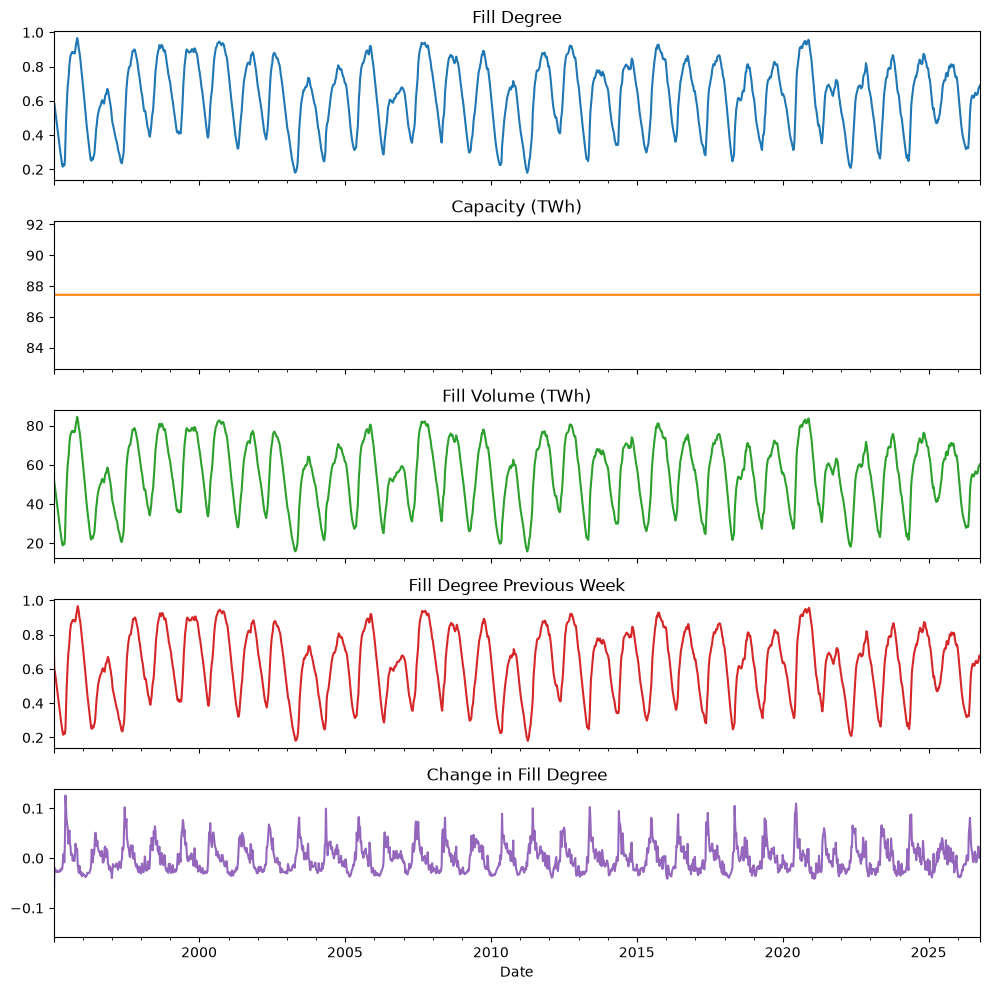

In [10]:
import matplotlib.pyplot as plt

df.set_index("Date")[cols].plot(subplots=True, figsize=(10, 10), legend=False, title=cols)      # one subplot per column
plt.tight_layout()
plt.show()

#### All columns together (normalized)
Each column is min-max scaled to 0-1. `Capacity (TWh)` is constant, so its range is 0.
I replace that range with 1 to avoid division by zero, and the line stays at 0 instead of disappearing.

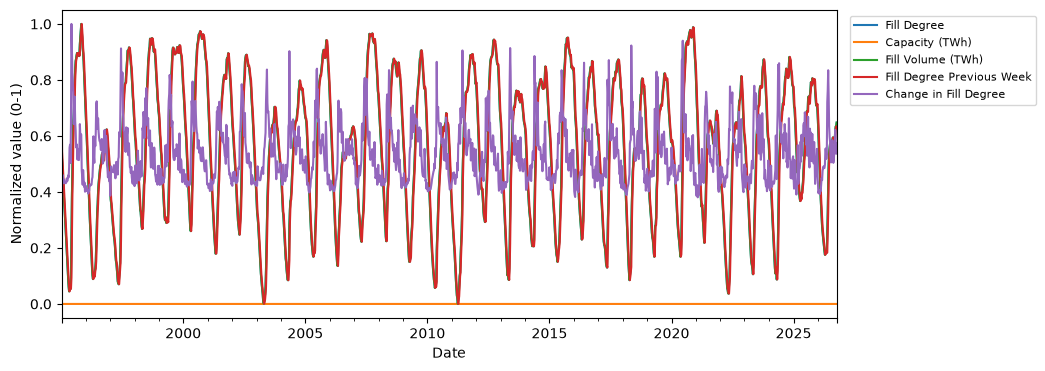

In [11]:
x = df.set_index("Date")[cols]
x = (x - x.min()) / (x.max() - x.min()).replace(0, 1)      # min - max
x.plot(figsize=(10, 4), ylabel="Normalized value (0-1)").legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### 5. Cross-border flows from ENTSO-E
Physical cross border flows (MW) between each Norwegian bidding zone and its neighbours for the last two years.
Each connection is fetched in two directions: **out** (from Norway) and **in** (into Norway).

In [12]:
import glob, os, time
import pandas as pd
from entsoe import EntsoePandasClient
from entsoe.exceptions import NoMatchingDataError, InvalidBusinessParameterError

client = EntsoePandasClient(api_key=os.getenv("ENTSOE_API_TOKEN"))      # token from .env
END = pd.Timestamp.now(tz="Europe/Oslo").normalize()
START = pd.Timestamp(year=END.year - 2, month=1, day=1, tz="Europe/Oslo")      # last two years
# Norwegian bidding zones and their neighbours (pairs without data are skipped)
CONNECTIONS = [("NO_1", "SE_3"), ("NO_2", "DK_1"), ("NO_2", "NL"), ("NO_2", "DE_LU"), ("NO_2", "GB"),
               ("NO_3", "SE_2"), ("NO_4", "SE_1"), ("NO_4", "SE_2"), ("NO_4", "FI")]

In [13]:
def fetch(a, b):
    """Hourly flow in MW from zone a to zone b (None if ENTSO-E has no data)."""
    for _ in range(3):
        try:
            return client.query_crossborder_flows(a, b, start=START, end=END).resample("h").mean().dropna()
        except (NoMatchingDataError, InvalidBusinessParameterError):
            return None
        except Exception as e:                      # temporary error: wait and try again
            print(f"  {a}->{b}: {type(e).__name__}, retrying")
            time.sleep(30)

#the download takes long time, so the result is cached in a file
CACHE = (sorted(glob.glob("flows_*.pkl")) or [f"flows_{END.date()}.pkl"])[-1]
if os.path.exists(CACHE):
    flows = pd.read_pickle(CACHE)
else:
    flows = {}                                      
    for zone, other in CONNECTIONS:
        for d, (a, b) in {"out": (zone, other), "in": (other, zone)}.items():      # out = from Norway, in = into Norway
            s = fetch(a, b)
            if s is not None and not s.empty:
                flows[(f"{zone}-{other}", d)] = s
            print(zone, other, d, 0 if s is None else len(s), "hours")
    assert flows, "No flow data retrieved - check the ENTSO-E token"
    pd.to_pickle(flows, CACHE)

pd.DataFrame([(c, d, len(s), s.index.min().date(), s.index.max().date()) for (c, d), s in flows.items()],
             columns=["connection", "direction", "hours", "first_day", "last_day"])

,connection,direction,hours,first_day,last_day
0,NO_1-SE_3,out,24527,2024-01-01,2026-10-18
1,NO_1-SE_3,in,24527,2024-01-01,2026-10-18
2,NO_2-DK_1,out,24527,2024-01-01,2026-10-18
3,NO_2-DK_1,in,24527,2024-01-01,2026-10-18
4,NO_2-NL,out,24527,2024-01-01,2026-10-18
5,NO_2-NL,in,24527,2024-01-01,2026-10-18
6,NO_2-DE_LU,out,24527,2024-01-01,2026-10-18
7,NO_2-DE_LU,in,24527,2024-01-01,2026-10-18
8,NO_2-GB,out,24527,2024-01-01,2026-10-18
9,NO_2-GB,in,24527,2023-12-31,2026-10-18


### 6. Insert the data into Cassandra with Spark

In [14]:
import subprocess, time

def cql(statement):
    #run a CQL statement in the cassandra container
    for i in range(18):
        r = subprocess.run(["docker", "exec", "cassandra", "cqlsh", "-e", statement], capture_output=True, text=True)
        if r.returncode == 0:
            return r.stdout
        print(f"Waiting for Cassandra ({i + 1}/18) ...")
        time.sleep(10)
    raise RuntimeError(r.stderr)

#partition key (connection, direction), rows sorted by time
cql("CREATE KEYSPACE IF NOT EXISTS ind320 WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1};")
cql("CREATE TABLE IF NOT EXISTS ind320.crossborder_flows (connection text, direction text, ts timestamp, mw double, "
    "PRIMARY KEY ((connection, direction), ts));")

#test the spark cassandra connection
CASS = "org.apache.spark.sql.cassandra"
OPT = dict(table="crossborder_flows", keyspace="ind320")
rows_in_table = spark.read.format(CASS).options(**OPT).load().count()
print("Spark-Cassandra connection works. Rows in table:", rows_in_table)

Spark-Cassandra connection works. Rows in table: 441486


In [15]:
from pyspark.sql import functions as F

#connection, direction, time as epoch seconds, MW
rows = [(c, d, int(t.timestamp()), float(v)) for (c, d), s in flows.items() for t, v in s.items()]
(spark.createDataFrame(rows, "connection string, direction string, epoch long, mw double")
      .select("connection", "direction", F.timestamp_seconds("epoch").alias("ts"), "mw")
      .write.format(CASS).options(**OPT).mode("append").save())
print("Rows written to Cassandra:", len(rows))

Rows written to Cassandra: 441486


### 7. Extract the relevant columns with Spark
Spark reads the table from Cassandra and keeps `connection`, `direction`, `ts` and `mw`, plus `year` and `month`.

In [16]:
spark.conf.set("spark.sql.session.timeZone", "Europe/Oslo")      # year and month in norsk time

#spark reads the table and keeps the relevant columns, plus year and month
flows_sdf = (spark.read.format(CASS).options(**OPT).load()
             .select("connection", "direction", "ts", "mw")
             .withColumn("year", F.year("ts")).withColumn("month", F.month("ts")).cache())
print("Rows read from Cassandra:", flows_sdf.count())
flows_sdf.show(5)

CONN, YEAR = "NO_2-DK_1", 2025      # chosen connection and year for the plots

Rows read from Cassandra: 441486
+----------+---------+-------------------+------+----+-----+
|connection|direction|                 ts|    mw|year|month|
+----------+---------+-------------------+------+----+-----+
| NO_4-SE_1|      out|2024-01-01 00:00:00|343.99|2024|    1|
| NO_4-SE_1|      out|2024-01-01 01:00:00|241.09|2024|    1|
| NO_4-SE_1|      out|2024-01-01 02:00:00|119.29|2024|    1|
| NO_4-SE_1|      out|2024-01-01 03:00:00|   0.0|2024|    1|
| NO_4-SE_1|      out|2024-01-01 04:00:00|   0.0|2024|    1|
+----------+---------+-------------------+------+----+-----+
only showing top 5 rows



### 8. Plots
- Pie chart: total flow in and out of Norway for one connection and one year.
- Line plot: the first month of a year, one line per connection and direction.

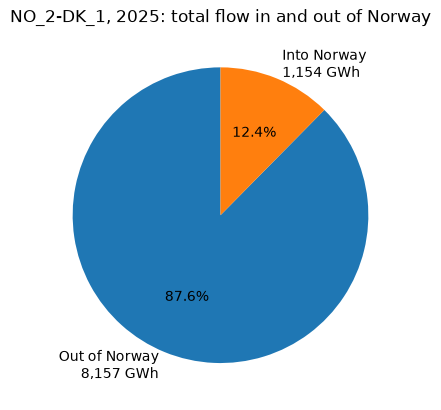

In [17]:
import matplotlib.pyplot as plt

#total flow per direction for the chosen connection and year, summed by spark
pie_rows = (flows_sdf.filter((F.col("connection") == CONN) & (F.col("year") == YEAR))
            .groupBy("direction").agg(F.sum("mw")).collect())
gwh = {r[0]: r[1] / 1000 for r in pie_rows}      # MWh -> GWh
plt.pie([gwh["out"], gwh["in"]], autopct="%1.1f%%", startangle=90,
        labels=[f"Out of Norway\n{gwh['out']:,.0f} GWh", f"Into Norway\n{gwh['in']:,.0f} GWh"])
plt.title(f"{CONN}, {YEAR}: total flow in and out of Norway")
plt.show()

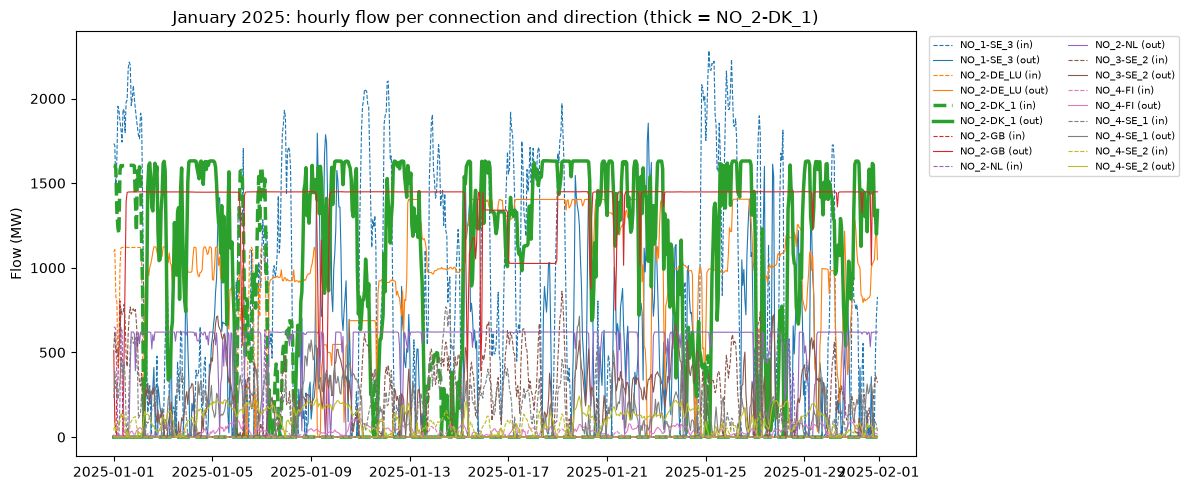

In [18]:
#january of the chosen year, all connections and both directions
jan = (flows_sdf.filter((F.col("year") == YEAR) & (F.col("month") == 1))
       .select("connection", "direction", F.col("ts").cast("long").alias("t"), "mw").collect())
line_df = pd.DataFrame([r.asDict() for r in jan])
line_df["ts"] = pd.to_datetime(line_df["t"], unit="s", utc=True).dt.tz_convert("Europe/Oslo").dt.tz_localize(None)

#one line per connection and direction
colors = {c: f"C{i}" for i, c in enumerate(sorted(line_df["connection"].unique()))}
fig, ax = plt.subplots(figsize=(12, 5))
for (conn, d), g in line_df.sort_values("ts").groupby(["connection", "direction"]):
    ax.plot(g["ts"], g["mw"], color=colors[conn], linestyle="-" if d == "out" else "--",
            linewidth=2.5 if conn == CONN else 0.8, label=f"{conn} ({d})")
ax.set(ylabel="Flow (MW)", title=f"January {YEAR}: hourly flow per connection and direction (thick = {CONN})")
ax.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### 9. Insert the Spark-extracted data into MongoDB
Spark groups the data into one document per connection, direction, year and month. Each document holds the hourly timestamps (`ts`) and flow values (`mw`) as lists, so the Streamlit app only needs small queries.

In [19]:
from datetime import datetime, timezone
from pymongo import MongoClient

#spark groups the data
monthly = (flows_sdf.groupBy("connection", "direction", "year", "month")
           .agg(F.sort_array(F.collect_list(F.struct(F.col("ts").cast("long").alias("t"), "mw"))).alias("points"))
           .collect())
docs = [{"connection": r.connection, "direction": r.direction, "year": r.year, "month": r.month,
         "ts": [datetime.fromtimestamp(p.t, tz=timezone.utc) for p in r.points], "mw": [p.mw for p in r.points]}
        for r in monthly]

collection = MongoClient(os.getenv("MONGO_URI"))["ind320"]["crossborder_flows"]
collection.delete_many({})          
collection.insert_many(docs)
print("Documents in MongoDB:", collection.count_documents({}))

Documents in MongoDB: 612


## Streamlit app
- Update your Streamlit app from part 1 of the project according to the following points.
- If you have something you would like to keep on page four, move it to a new page five.
- Establish a connection to the API of Magasinstatistikk and use this instead of the now-deleted CSV file.
   - The selection slider that was on page three should now control the download interval, i.e., which data are downloaded.
   - Use radio buttons (st.radio) to select the type of areas (EL, NO, VASS) such that plots and LineChartColumn() show the corresponding graphics (e.g., lines) for each of the associated area numbers.
   - Reorganise pages two and three in the way you find most logical and user-friendly. Use an extra page if you need to. Solutions that deviate slightly from the descriptions above, but improve the experience are welcome.
- Establish a connection with your MongoDB database. When running this at streamlit.io, remember to copy your secrets to the webpage instead of exposing them on GitHub.
- On a separate page, split the view into two columns using st.columns.
    - On the left side, use radio buttons (st.radio) to select a connection and a different control to select the year, and display a pie chart like in the Jupyter Notebook.
    - On the right side, use pills (st.pills) to select which months to include and display a line plot like in the Jupyter Notebook (but for any set of months).
    - Below the columns, insert an expander (st.expander) where you briefly document the source of the data shown on the page.

In [20]:
#streamlit app requirements
!cat ../requirements.txt

streamlit
pandas
matplotlib
requests
pymongo

In [21]:
#folder structure
!cat ../README.md

IND320
├── .streamlit/
│   └── config.toml          
│
├── modules/
│   ├── data_loader.py       
│   └── mongo.py            
│
├── notebooks/
│   ├── project_work_part1.ipynb
│   └── project_work_part2.ipynb
│
├── pages/
│   ├── Page_2.py            
│   ├── Page_3.py         
│   └── Page_4.py           
│
├── video/
│   ├── video.ind320-kompresed- part 1.mp4
│   └── video.ind320-kompresed- part 2.mp4
│
├── .gitignore
├── README.md
├── requirements.txt
└── streamlit_app.py


In [22]:
!cat ../modules/data_loader.py

#loads the nve reservoir statistics directly from the NVE API (replaces the CSV file)
import pandas as pd
import requests
import streamlit as st

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# norsk to english names
RENAME = {
    "dato_Id": "Date",
    "omrType": "Area Type",
    "omrnr": "Area Number",
    "fyllingsgrad": "Fill Degree",
    "kapasitet_TWh": "Capacity (TWh)",
    "fylling_TWh": "Fill Volume (TWh)",
    "fyllingsgrad_forrige_uke": "Fill Degree Previous Week",
    "endring_fyllingsgrad": "Change in Fill Degree",
}
VALUE_COLS = ["Fill Degree", "Capacity (TWh)", "Fill Volume (TWh)",
              "Fill Degree Previous Week", "Change in Fill Degree"]
AREA_TYPES = ["EL", "NO", "VASS"]   # bidding zones, whole country, watercourse areas


@st.cache_data(ttl=3600, show_spinner="Downloading data from the NVE API ...")
def download_all() -> pd.DataFrame:
    """Download the full history for all areas once (the API has no date parameters). Cached for on

In [23]:
# page 1/homepage of the app
!cat ../streamlit_app.py

import streamlit as st
import random


#configure page settings
st.set_page_config(
    page_title="IND320", page_icon="💧", layout="wide"
)

#sidebar info
st.sidebar.title("Navigation")
st.sidebar.info(
    "Use the pages above to explore the other pages:\n\n"
    "- **Page 2** — reservoir table \n"
    "- **Page 3** — reservoir plot \n"
    "- **Page 4** — cross border flows \n"
)

#main page title and intro
st.title("💧IND320💧")
st.markdown(
    """
    Use the sidebar to navigate between pages.

    links to git and this app:
    - https://ind320-dakshi.streamlit.app
    - https://github.com/dakshiken/IND320
    
    """
)

#falling emojis using injected CSS animation

emoji = "Welcome 👋"
count = random.randint(3, 15)
spans = "".join(
    f'<span class="e" style="left:{random.randint(5, 95)}%; animation-delay:{random.uniform(0, 1):.1f}s">{emoji}</span>'
    for _ in range(count)
)

st.markdown(
    f"<style>@keyframes d{{to{{top:100vh;opacity:0}}}}.e{{position:fixed;top:0;font-size:3

In [24]:
# page 2 of the app
!cat ../pages/Page_2.py

import pandas as pd
import streamlit as st

from modules.data_loader import AREA_TYPES, VALUE_COLS, load_data

# Page configuration
st.set_page_config(page_title="Reservoir Table", page_icon="📊", layout="wide")
st.title("📊  Reservoir Table  📊")
st.markdown(
    "Data is downloaded live from the NVE Magasinstatistikk API. One row per area number. "
    "Each sparkline shows the trend for the selected months."
)

# EL (bidding zones), NO (whole country) or VASS (watercourse areas)
area_type = st.radio("Area type", AREA_TYPES, horizontal=True)
df = load_data(area_type=area_type)

# Sikre at Date er datetime og lag måned-slider
if not df.empty and "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"])
    
    # Konverter datoer til måneder for slideren
    month = df["Date"].dt.to_period("M")
    months = [str(period) for period in month.unique()]
    
    # Velg standardverdi (siste 5 år hvis tilgjengelig, ellers hele perioden)
    default_start = months[-60] if len(months) >=

In [25]:
# page 3 of the app
!cat ../pages/Page_3.py

import streamlit as st

from modules.data_loader import AREA_TYPES, VALUE_COLS, download_all, load_data

#page configuration
st.set_page_config(page_title="Reservoir Plot", page_icon="📈", layout="wide")
st.title("📈  Reservoir Plot  📈")

#months that the API provides, used as the options of the slider
months = sorted(download_all()["Date"].dt.to_period("M").astype(str).unique())

#area type (radio), column (selectbox) and download interval (select_slider)
col1, col2, col3 = st.columns([1, 1, 2])
with col1:
    area_type = st.radio("Area type", AREA_TYPES)
with col2:
    column_choice = st.selectbox("Column to plot", ["All columns"] + VALUE_COLS)
with col3:
    #slider decides which months are loaded
    start, end = st.select_slider(
        "Download interval (months)", options=months,
        value=(months[max(0, len(months) - 36)], months[-1]),
    )

#only the chosen area type and months are loaded
df = load_data(area_type, start, end)
if df.empty:
    st.warning("No data for this s

In [26]:
# page 4 of the app
!cat ../pages/Page_4.py

import calendar

import matplotlib.pyplot as plt
import streamlit as st

from modules.mongo import get_flows, get_options, get_totals

#oage configuration
st.set_page_config(page_title="Cross-border flows", page_icon="💦", layout="wide")
st.title("💦  Cross-border flows 💦")
st.markdown("Hourly physical flows (MW) between Norway and its neighbours, read from MongoDB.")

#connections and years that exist in the database
try:
    connections, years = get_options()
except Exception as e:
    st.error(f"Could not read from MongoDB: {e}")
    st.stop()

left, right = st.columns(2)

#pie chart of the total flow in and out of Norway for one connection and year
with left:
    st.subheader("Total flow in one year")
    connection = st.radio("Connection", connections)
    year = st.selectbox("Year", years, index=max(len(years) - 2, 0))   # last complete year
    totals = get_totals(connection, year)
    names = {"out": "Out of Norway", "in": "Into Norway"}
    directions = [d for d in ("out", "in")

In [27]:
# short summary of my git log
!git log --oneline

b10084a (HEAD -> main, origin/main, origin/HEAD) compresed screencast
c5d60a4 added slider to page 2
05cd66c (origin/dev, dev) finished , only missing screencast
1ea9345 clean up
5c2769d updated the readmefile
42d34db added the video to the ipynb part 1
988b93d har prøv å pushhe orginal videoen men det gikk ikke så måtte compresse fra 127,9 MB til under 25 mb, så kvaliteten på videon har gått ned veldig
75d40f0 found out i need to reeboot the app to get the chanhes to show
0a7b7b2 tring to fix a problrm
afd7c8e Merge branch 'main' of https://github.com/dakshiken/IND320-main-3
4b80217 test
ac71cdb Added Dev Container Folder
717f310 small changes
60e813d fix
43a7a2e finished work
ee831c4 test
c70b471 test
9212fd4 first commit


## AI usage

Ai was used to a limited extent during the development of this application.

**Models Used:**
- Google Gemini

**Scope of Usage:**
- Streamlit syntax lookups and HTML/CSS styling syntax
- Debugging (pasting error outputs)
- Helped me relly musch to understand more the NVE and ENTSO-E APIs Spark, Cassandra, MongoDB etc

## developers log

i started with the nve magasinstatistikk api in swagger. all endpoints are get requests without parameters, so i download the whole history in one call and filter it in pandas. the time columns were a problem in part 1, so now i use dato_id (always a sunday) as the date. the api covers the whole country, five bidding zones and four watercourse areas. i recreated the part 1 plots from the api data. i also fixed the peer review comment about the capacity line: it is constant, so the min-max scaling divided by zero. now a range of zero is replaced by 1, and the line stays visible.
most of the time went into the setup. cassandra runs in docker, and spark needs a connector that matches its version. at first my notebook ran inside a linux dev container with pyspark 4 and no docker, which gave connector errors. running locally with pyspark 3.5.1 and java 11 solved this. my first entso-e request gave http 401 until i had a valid token in the .env file. later the cassandra container would not restart (it got no network address), so the notebook now creates a fresh container with fixed addresses.
for entso-e i used the entsoe-py library and asked for the physical cross border flows between each norwegian bidding zone and its neighbours, from 1 january two years ago until today. each connection is fetched in two directions, called "out" (from norway) and "in" (into norway). the library sends one request per month, so the download is slow; failed requests are retried and the result is saved in a cache file. spark wrote the hourly values to a cassandra table with (connection, direction) as partition key and time as clustering key. i read the table back with spark, kept only the relevant columns and added year and month. i made a pie chart of the total flow in and out for one connection and year, and a line plot of january with one line per connection and direction.ladtly spark grouped the data into one mongodb document per connection, direction, year and month, so the streamlit app only needs small queries.
for the streamlit app i replaced the csv file in modules/data_loader.py with a download from the nve api. the api has no date parameters, so the full history is downloaded once and cached, and the slider on page 3 decides which months are loaded. radio buttons choose el, no or vass, with one table row and one plot line per area number. page 4 reads the flow data from mongodb (the connection string is in streamlit secrets) and has the pie chart, month pills and an expander.after recording the screencast i made a small change , i added a slider on page 2

## Evaluation
- The uploaded PDF, GitHub repository, Streamlit app, and screencast will be assessed according to the recipe above.
    - By one fellow student in peer review.
    - By Liland or Osman.
- TA/Teacher's feedback will be short and instructive regarding points of improvement and fulfilment of requirements.
- Final fulfilment of the course will be based on the four rounds of hand-ins seen as a whole.

In [28]:
from IPython.display import Video
Video("../video/video.ind320-kompresed- part 2.mp4", width=600)
